In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


orders_df = pd.read_excel('./data/orders.xlsx')
products_df = pd.read_excel('./data/products.xlsx')

res_df = orders_df.copy().merge(products_df, 'inner', on='product_id')
res_df.head()

,order_id,accepted_at,product_id,quantity,regular_price,price,cost_price,level1,level2,name
0,1517514900,2022-01-13 16:48:19,17122,1,169,169,74,Рыбная гастрономия,Нерыбные продукты моря,Крабовые палочки Меридиан
1,1517430051,2022-01-13 16:46:53,17122,1,169,169,74,Рыбная гастрономия,Нерыбные продукты моря,Крабовые палочки Меридиан
2,1517578174,2022-01-13 18:12:30,17122,1,169,169,74,Рыбная гастрономия,Нерыбные продукты моря,Крабовые палочки Меридиан
3,1517466327,2022-01-13 15:11:12,22199,1,219,219,130,Сыры,Мягкие сыры,Сыр Самокат
4,1517429157,2022-01-13 19:15:59,22199,1,219,219,130,Сыры,Мягкие сыры,Сыр Самокат


Самая ходовая товарная группа

По какой категории товаров продано больше всего позиций?

1. Подкрепите свой ответ таблицей, в которой рассчитано количество проданных штук товара в каждой товарной категории.
2. Дополнительно постройте на основании этой таблицы barchart.
3. Проверьте, чтобы все подписи на вашем графике выглядели читаемо и понятно. Этот график должен быть сходу понятен стороннему наблюдателю.

                          level1  quantity
1         Безалкогольные напитки       534
11            Молочная продукция       483
19                  Свежие овощи       262
10                     Кулинария       250
0                        Бакалея       239
25  Хлеб и хлебобулочные изделия       218
21                         Снэки       212
20                 Свежие фрукты       184
6         Замороженная продукция       175
7           Кондитерские изделия       138


/var/folders/yr/dy9t4b0158d_7x9jkhfr5zlm0000gn/T/ipykernel_31552/3725504906.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  fig.set_xticklabels(fig.get_xticklabels(), rotation=90)


Text(0, 0.5, 'Кол-во проданной продукции')

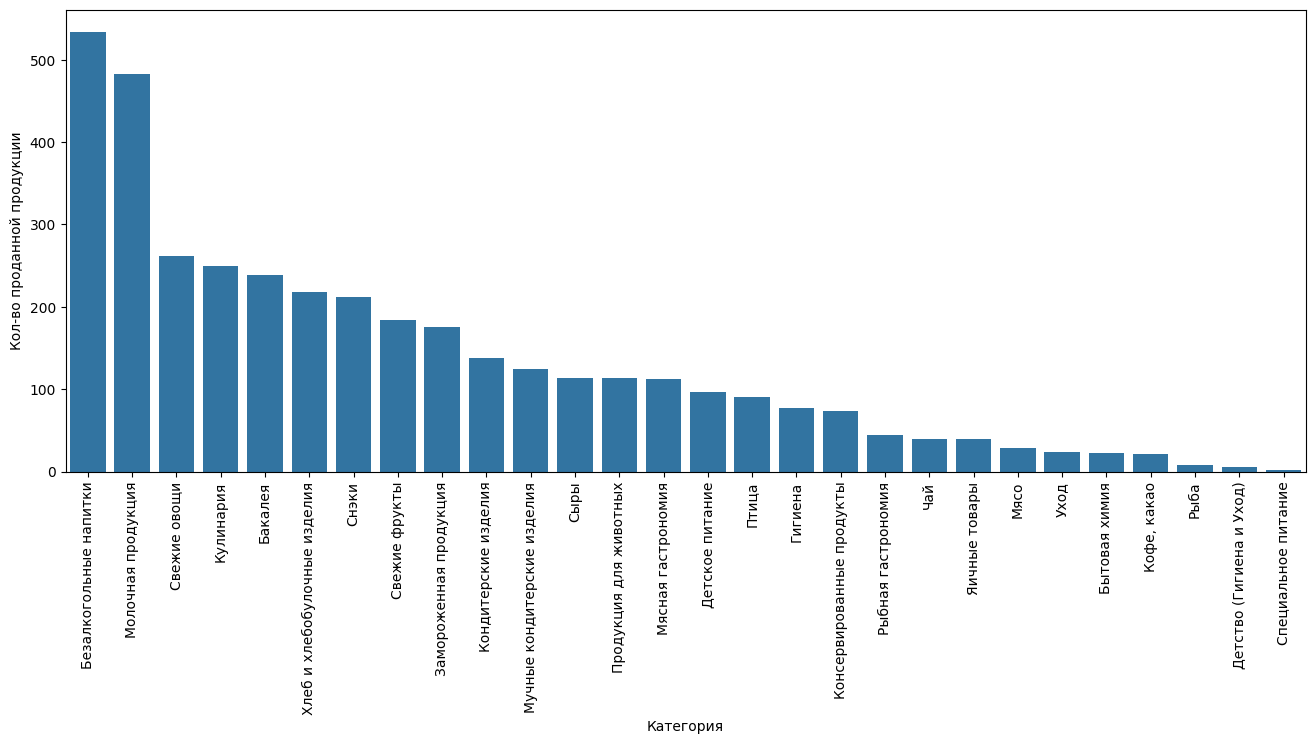

In [ ]:
plt.figure(figsize=(16, 6))

prod_group = res_df.copy()
prod_group = prod_group.groupby(['level1'])['quantity'].agg('sum').reset_index()
print(prod_group.sort_values('quantity', ascending=False).head(10))

fig = sns.barplot(prod_group.sort_values('quantity', ascending=False), x='level1', y='quantity')
fig.set_xticklabels(fig.get_xticklabels(), rotation=90)
fig.set_xlabel('Категория')
fig.set_ylabel('Кол-во проданной продукции')
fig.set_title('Количество проданных товаров по категориям') #CL

Распределение продаж по подкатегориям

Оцените распределение количества проданных позиций в каждой товарной 
категории (level1) по подкатегориям (level2). Проиллюстрируйте свой результат расчетной таблицей.

<!-- Что значит оценить?  -->

In [ ]:
work_df = res_df.copy()
prod_group_sub = work_df.groupby(['level1', 'level2'])['quantity'].agg('sum').reset_index()
prod_group = work_df.groupby(['level1'])['quantity'].agg('sum').reset_index()

prod_group_sub= prod_group_sub.merge(prod_group, how='left', on='level1')
prod_group_sub.columns =['level1', 'level2', 'quantity_sub', 'all_cat_quant']

prod_group_sub['sub_cat_relevant'] = round((prod_group_sub['quantity_sub'] / prod_group_sub['all_cat_quant'] ) * 100, 2 )#.astype('str') + '%'
prod_group_sub.sort_values(['level1', 'sub_cat_relevant'], ascending=(True, False)).head(10)
prod_group_sub.sort_values(['sub_cat_relevant'], ascending=False).head(20)



,level1,level2,quantity_sub,all_cat_quant,sub_cat_relevant
99,Яичные товары,Яйцо куриное,40,40,100.00
69,Мясо,Мясо животных охлажденное,29,29,100.00
73,Рыба,Рыба и морепродукты замороженные,8,8,100.00
72,Птица,Мясо птицы охлажденное,90,90,100.00
95,Хлеб и хлебобулочные изделия,Хлеб и хлебобулочные изделия,218,218,100.00
87,Специальное питание,Диетическое питание,2,2,100.00
54,Кулинария,Готовые блюда,248,250,99.20
86,Снэки,Снэки соленые,180,212,84.91
63,Мучные кондитерские изделия,Мучные кондитерские изделия,104,124,83.87
51,"Кофе, какао",Кофе,15,21,71.43


Найти средний чек в заданную дату
Какой средний чек был 13.01.2022?

(3323, 7)
Orders count 544, Max price 5518, Min price 84, Median 666.5
Answer 915.64


(0.0, 2500.0)

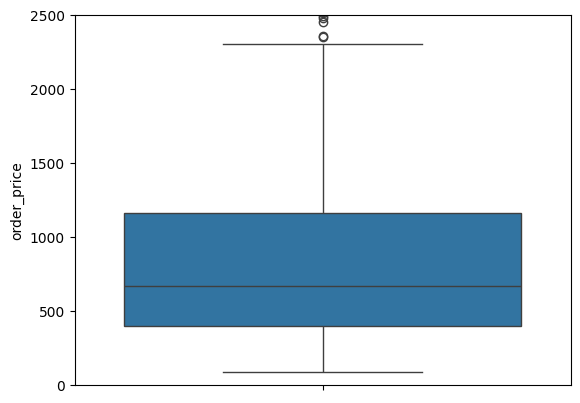

In [232]:
work_df = orders_df.copy()

print(orders_df.shape)
work_df['ymd'] = pd.to_datetime(work_df['accepted_at']).dt.strftime('%Y-%m-%d')
correct_date_df = work_df[work_df['ymd'] == '2022-01-13']
correct_date_df['price_at_quant'] = correct_date_df['price'] * correct_date_df['quantity']
orders_value_df = correct_date_df.groupby(['order_id'])['price_at_quant'].agg(order_price = 'sum').reset_index()
answer = orders_value_df['order_price'].mean()

print(f"Orders count {len(orders_value_df['order_id'].unique())}, Max price {orders_value_df['order_price'].max()}, Min price {orders_value_df['order_price'].min()}, Median {orders_value_df['order_price'].median()}")
print('Answer', round(answer, 2))

fig = sns.boxplot(orders_value_df, y='order_price')
fig.set_ylim(0, 2500)



Доля промо в заданной категории

Когда товар продается по промо-акции, его базовая цена не совпадает с фактической ценой.

Вам необходимо:

1. Посчитать, какую долю от общих продаж категории Сыры занимают промо (в штуках)
2. Построить пайчарт, который это проиллюстрирует. На графике должны быть видны группы, соответствующие доли и понятные подписи к ним.

35 30.7%


([<matplotlib.patches.Wedge at 0x146e7da30>,
 [Text(-0.6267888038687083, 0.9039556379296687, 'Without discount'),
  Text(0.7122599082207619, -1.0272223825157587, 'With discount')],
 [Text(-0.34188480211020444, 0.4930667115980011, '69%'),
  Text(0.4273559449324571, -0.6163334295094552, '31%')])

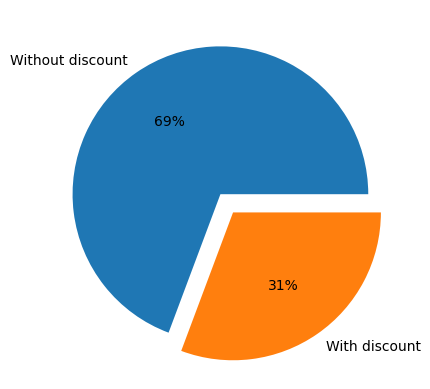

In [299]:
work_df = res_df.copy()

work_df = work_df[work_df['level1']=='Сыры']
work_df =work_df[['order_id', 'product_id', 'quantity', 'regular_price',\
       'price', 'cost_price']]

work_df['discount'] = work_df['regular_price'] - work_df['price']
disc_total_abs = work_df[work_df['discount']> 0].quantity.sum()
reg_total_abs = work_df.quantity.sum()
answer = disc_total_abs
answer_percent = str(round(disc_total_abs/reg_total_abs * 100, 2) ) + '%'
print(answer, answer_percent)

work_df['is_discount'] = ~(work_df['discount'] == 0)

answer_df = work_df.groupby(['is_discount'])['quantity'].agg('sum').reset_index()
answer_df

plt.pie(answer_df['quantity'], explode=[0, 0.15], labels=[f'Without discount', 'With discount'], autopct='%.0f%%')

Посчитать маржу по категориям

Нужно посчитать маржу:

1. В рублях
2. В %

Сделать это нужно по всем категориям level1 и отобразить с помощью 2 горизонтальных барчартов. Все подписи должны быть читаемыми и понятными.

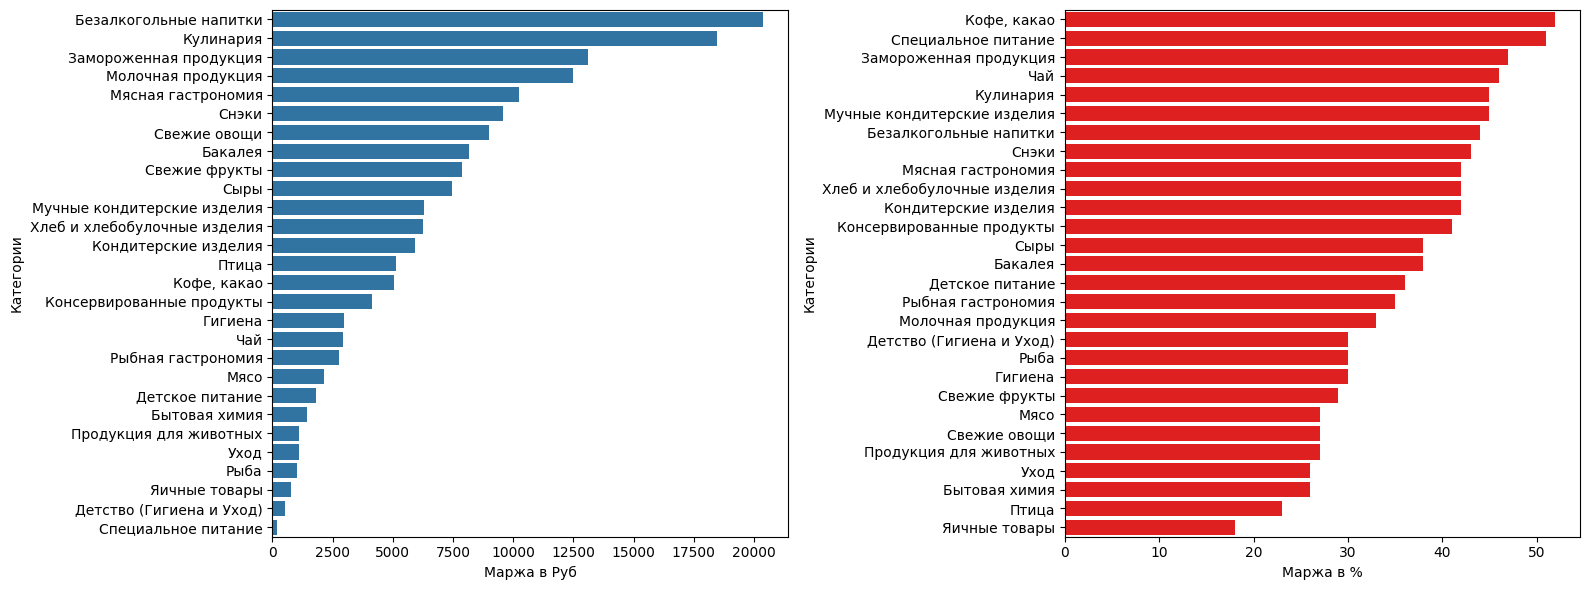

In [23]:
work_df = res_df.copy()

work_df['revenue'] = work_df['price'] * work_df['quantity']
work_df['cost'] = work_df['quantity'] * work_df['cost_price']
work_df['profit'] = work_df['revenue'] - work_df['cost']


cat_inspect_df = work_df.groupby(['level1']).agg(profit=('profit', 'sum'), revenue=('revenue', 'sum')).reset_index()
cat_inspect_df['margin_pct'] = round((cat_inspect_df['profit'] / cat_inspect_df['revenue']) * 100)
cat_inspect_df['margin_rub'] = cat_inspect_df['profit']
cat_inspect_df



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
plot = sns.barplot(cat_inspect_df.sort_values('margin_rub', ascending=False), x='margin_rub', y='level1', ax=ax1)
plot.set(xlabel = 'Маржа в Руб', ylabel = 'Категории')
plot = sns.barplot(cat_inspect_df.sort_values('margin_pct', ascending=False), x='margin_pct', y='level1', ax=ax2, color='red')
plot.set(xlabel = 'Маржа в %', ylabel = 'Категории')


plt.tight_layout()


ABC анализ

Сделайте ABC-анализ продаж по количеству
Сделайте ABC-анализ по сумме продаж
Сделайте новый столбец, в котором будет итоговая группа на основании двух анализов. Например: A C.

Важно: предлагаем провести ABC-анализ по подкатегориям, а не по отдельным товарам. Имеющихся у нас данных за небольшой период недостаточно для качественного анализа на уровне товаров. К тому же, количество товаров слишком велико, что может также исказить результаты. А ABC-анализ по подкатегориям даст более адекватную и интерпретируемую картину.


In [ ]:
# level 2
# по количеству
import numpy as np

work_df = res_df.copy()

count_df = work_df.groupby(['level2'])['quantity'].agg('sum').reset_index().sort_values('quantity', ascending=False)
count_df['quant_relativ'] = round(count_df['quantity'] / count_df['quantity'].sum() * 100, 3)
count_df['cumsum_diff'] = count_df['quant_relativ'].cumsum()
count_df['quant_abc'] = np.where(count_df['cumsum_diff']<= 80, 'A', np.where(count_df['cumsum_diff']<= 95, 'B', 'C'))

# сумме продаж
work_df['revenue'] = work_df['price'] * work_df['quantity']
revenue_df = work_df.groupby(['level2'])['revenue'].agg('sum').reset_index().sort_values('revenue', ascending=False)
revenue_df['revenue_relativ'] = round((revenue_df['revenue'] / revenue_df['revenue'].sum()) * 100, 2)
revenue_df['cumsum_revenue'] = round(revenue_df['revenue_relativ'].cumsum(), 1)
revenue_df['revenue_abc'] = np.where(revenue_df['cumsum_revenue'] <= 80, 'A', np.where(revenue_df['cumsum_revenue'] <= 95, 'B', 'C'))

res_abc_df = revenue_df[['level2', 'revenue_abc']].merge(
    count_df[['level2', 'quant_abc']],
    on='level2',
    how='inner'  
)
res_abc_df['res_abc'] = res_abc_df['quant_abc'] + res_abc_df['revenue_abc']
res_abc_df.sort_values('res_abc').head(15)



,level2,revenue_abc,quant_abc,res_abc
0,Готовые блюда,A,A,AA
24,Бумажная продукция,A,A,AA
23,Современные кондитерские изделия,A,A,AA
22,Молочно-десертные продукты,A,A,AA
21,Мороженое,A,A,AA
18,Мягкие сыры,A,A,AA
16,Кисломолочные традиционные продукты,A,A,AA
15,Воды питьевые,A,A,AA
14,Соковая продукция,A,A,AA
25,Яйцо куриное,A,A,AA
